# C6 — Statistical comparison across Study C

All 15 final Study C models (C1-R 6, C2 6, C3 3) plus the B2 baselines CVSS v3 and point-in-time EPSS: 10 seeds each. Global test metrics; monthly MAP (primary), P@10, NDCG@10, NDCG@100, MRR over 46 monthly batches; Friedman + Nemenyi with critical-difference diagrams; Wilcoxon vs the best mean-rank model and vs EPSS-PIT, Holm-adjusted. Design: Study C addendum 2 (commit 59bd4b1).

Reads saved outputs; run: `python -m src.models.c6_statistics` (~3 min). Note: `scikit-posthocs` 0.16 `critical_difference_diagram` overwrites the p-value matrix it is given with 0/1 flags — the code passes a copy (found and fixed during this run).

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

## Global test metrics (10 seeds, mean ± std)

In [2]:
pd.read_csv("outputs/c6_global_summary.csv", index_col=0)

,pr_auc,precision_at_10,precision_at_100,ndcg_at_100,mrr,roc_auc
method,,,,,,
C1R:logreg,0.0235 ± 0.0,0.2 ± 0.0,0.12 ± 0.0,0.1404 ± 0.0,0.25 ± 0.0,0.8344 ± 0.0
C1R:xgboost,0.022 ± 0.0002,0.16 ± 0.049,0.132 ± 0.006,0.1394 ± 0.0046,0.1291 ± 0.0236,0.8274 ± 0.0023
C3:ft_transformer,0.021 ± 0.0017,0.26 ± 0.049,0.117 ± 0.019,0.1442 ± 0.0124,0.425 ± 0.2155,0.8123 ± 0.0105
C2:lgbm_lambdamart,0.0207 ± 0.0009,0.3 ± 0.0632,0.13 ± 0.01,0.1425 ± 0.0079,0.2136 ± 0.0415,0.8203 ± 0.0014
C2:xgb_lambdamart,0.0205 ± 0.0014,0.26 ± 0.049,0.129 ± 0.0114,0.1415 ± 0.0118,0.2526 ± 0.0701,0.8279 ± 0.0024
C2:xgb_pairwise,0.0194 ± 0.0007,0.22 ± 0.06,0.141 ± 0.0083,0.1507 ± 0.006,0.2258 ± 0.0637,0.8143 ± 0.0024
C2:lgbm_binary,0.0185 ± 0.0015,0.21 ± 0.07,0.123 ± 0.0149,0.1316 ± 0.0138,0.2187 ± 0.1157,0.833 ± 0.0034
C2:xgb_binary,0.0179 ± 0.0008,0.15 ± 0.0671,0.124 ± 0.0111,0.1291 ± 0.0087,0.142 ± 0.0359,0.828 ± 0.0019
baseline:epss_pit,0.0175 ± 0.0,0.2 ± 0.0,0.11 ± 0.0,0.1263 ± 0.0,0.25 ± 0.0,0.5962 ± 0.001


## Friedman across 17 methods (46 months)

In [3]:
pd.read_csv("outputs/c6_friedman.csv", index_col=0)[["statistic", "p_value", "n_months", "best_mean_rank"]]

,statistic,p_value,n_months,best_mean_rank
precision_at_10,48.061338,4.645767e-05,46,C1R:xgboost
ndcg_at_10,46.802604,7.309590e-05,46,C2:xgb_lambdamart
map,108.770673,7.677810e-16,46,C1R:logreg
mrr,24.448972,8.014680e-02,46,C1R:logreg
ndcg_at_100,62.976859,1.636723e-07,46,C1R:logreg


## Critical-difference diagrams

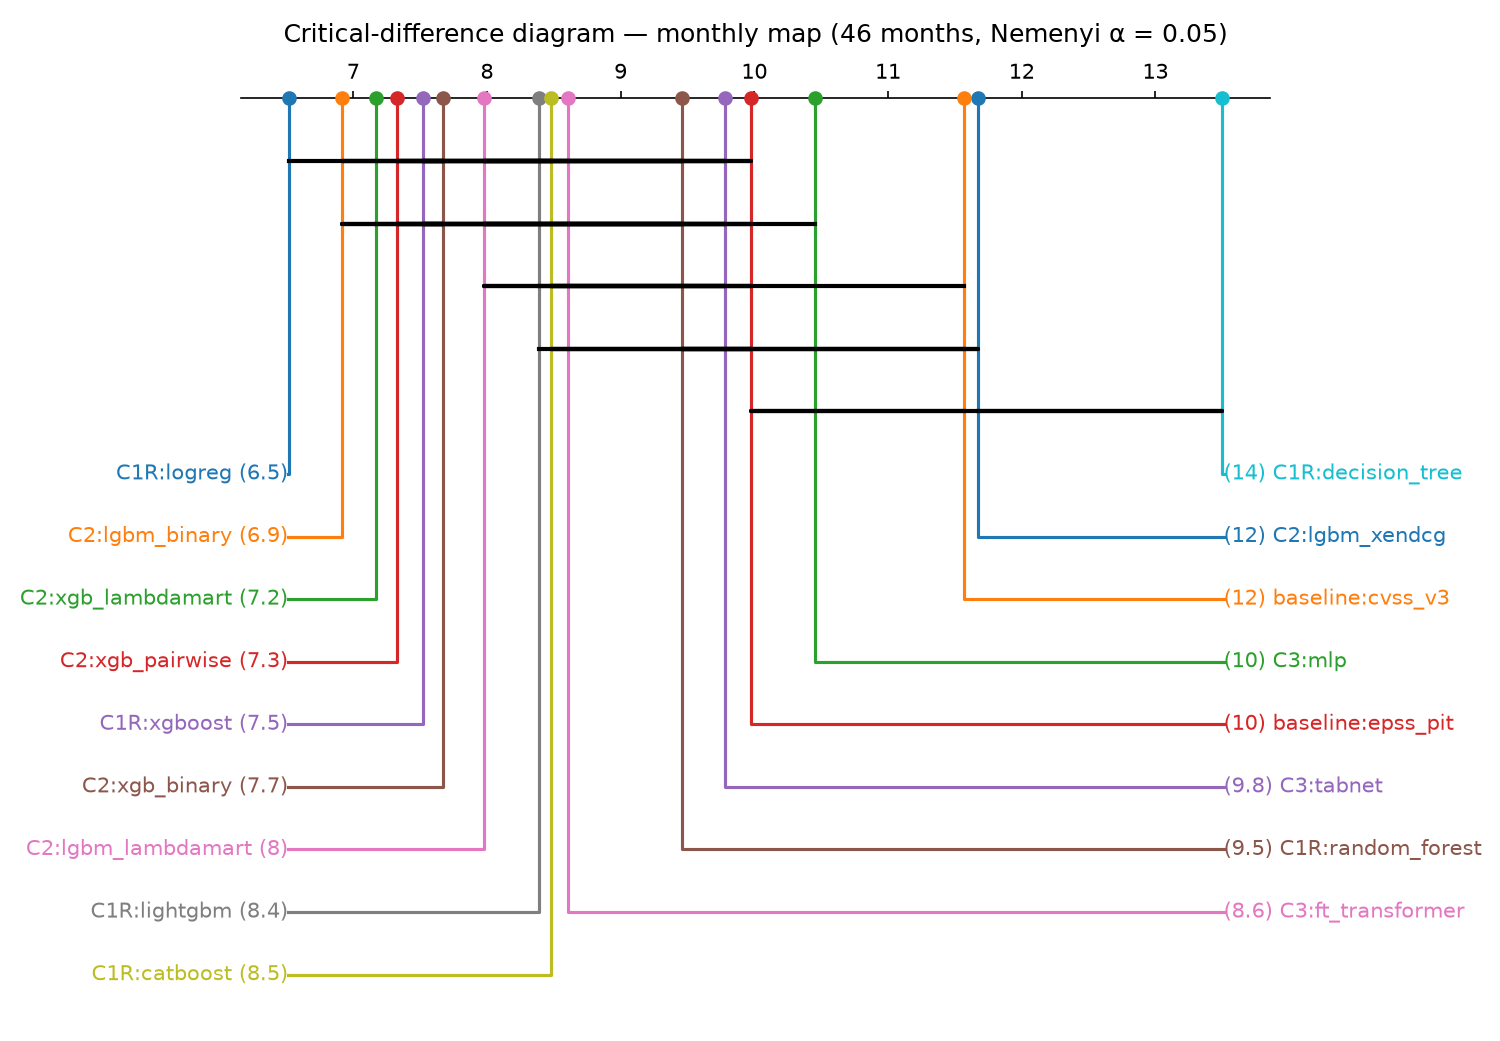

In [4]:
Image("outputs/c6_cd_map.png")

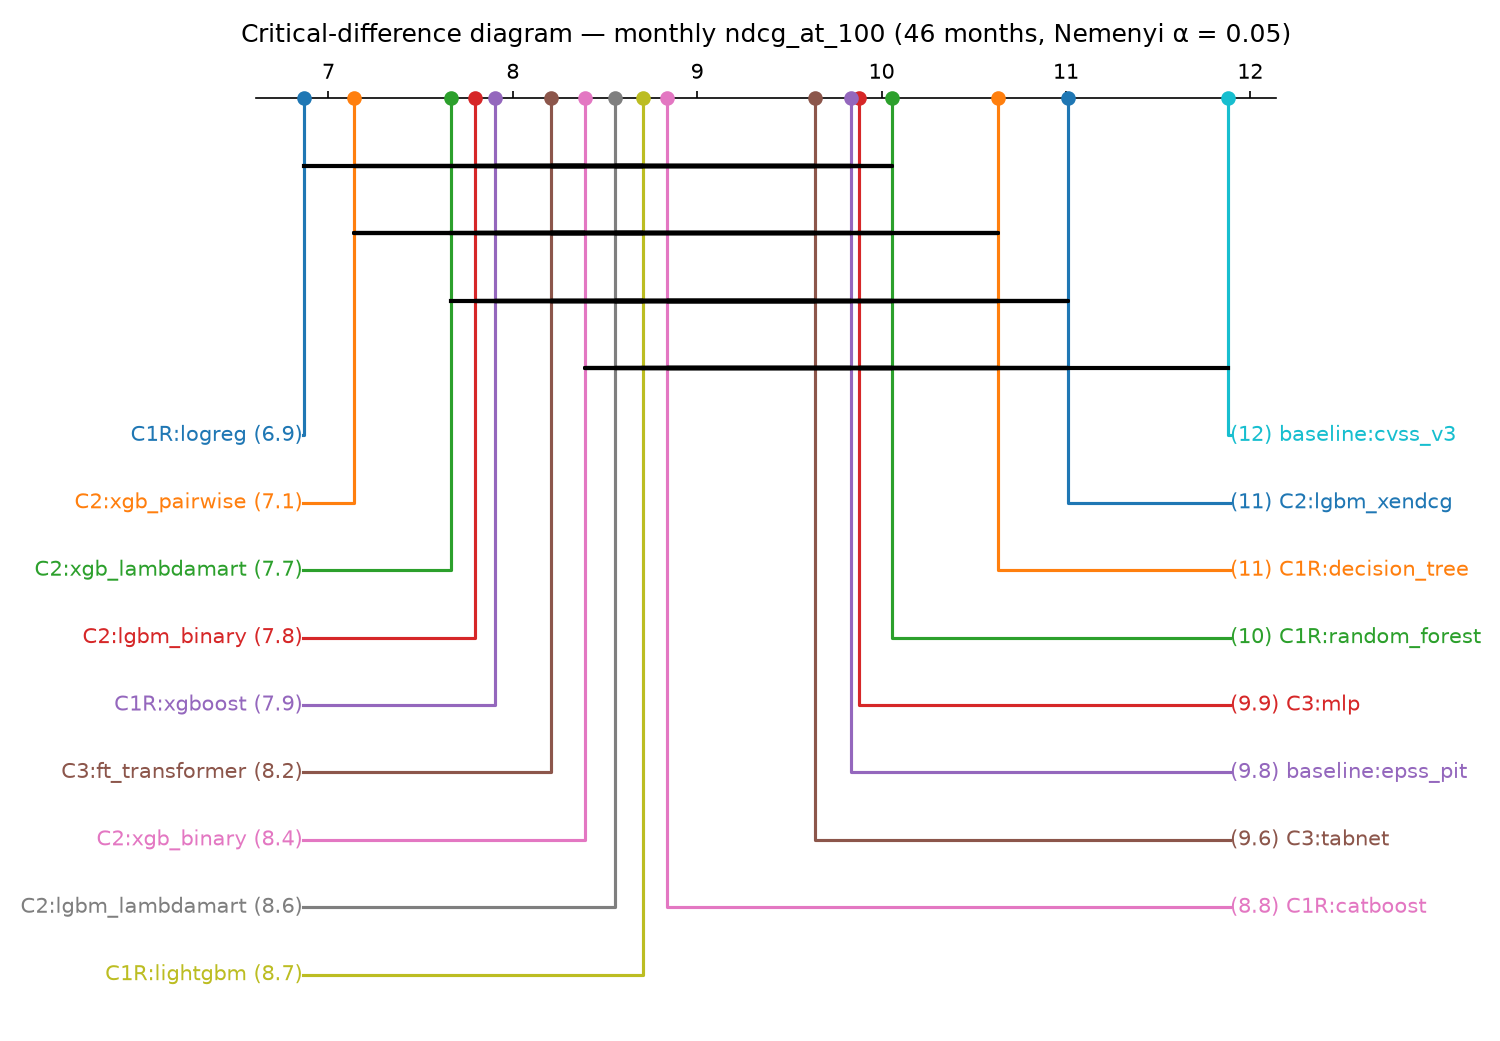

In [5]:
Image("outputs/c6_cd_ndcg_at_100.png")

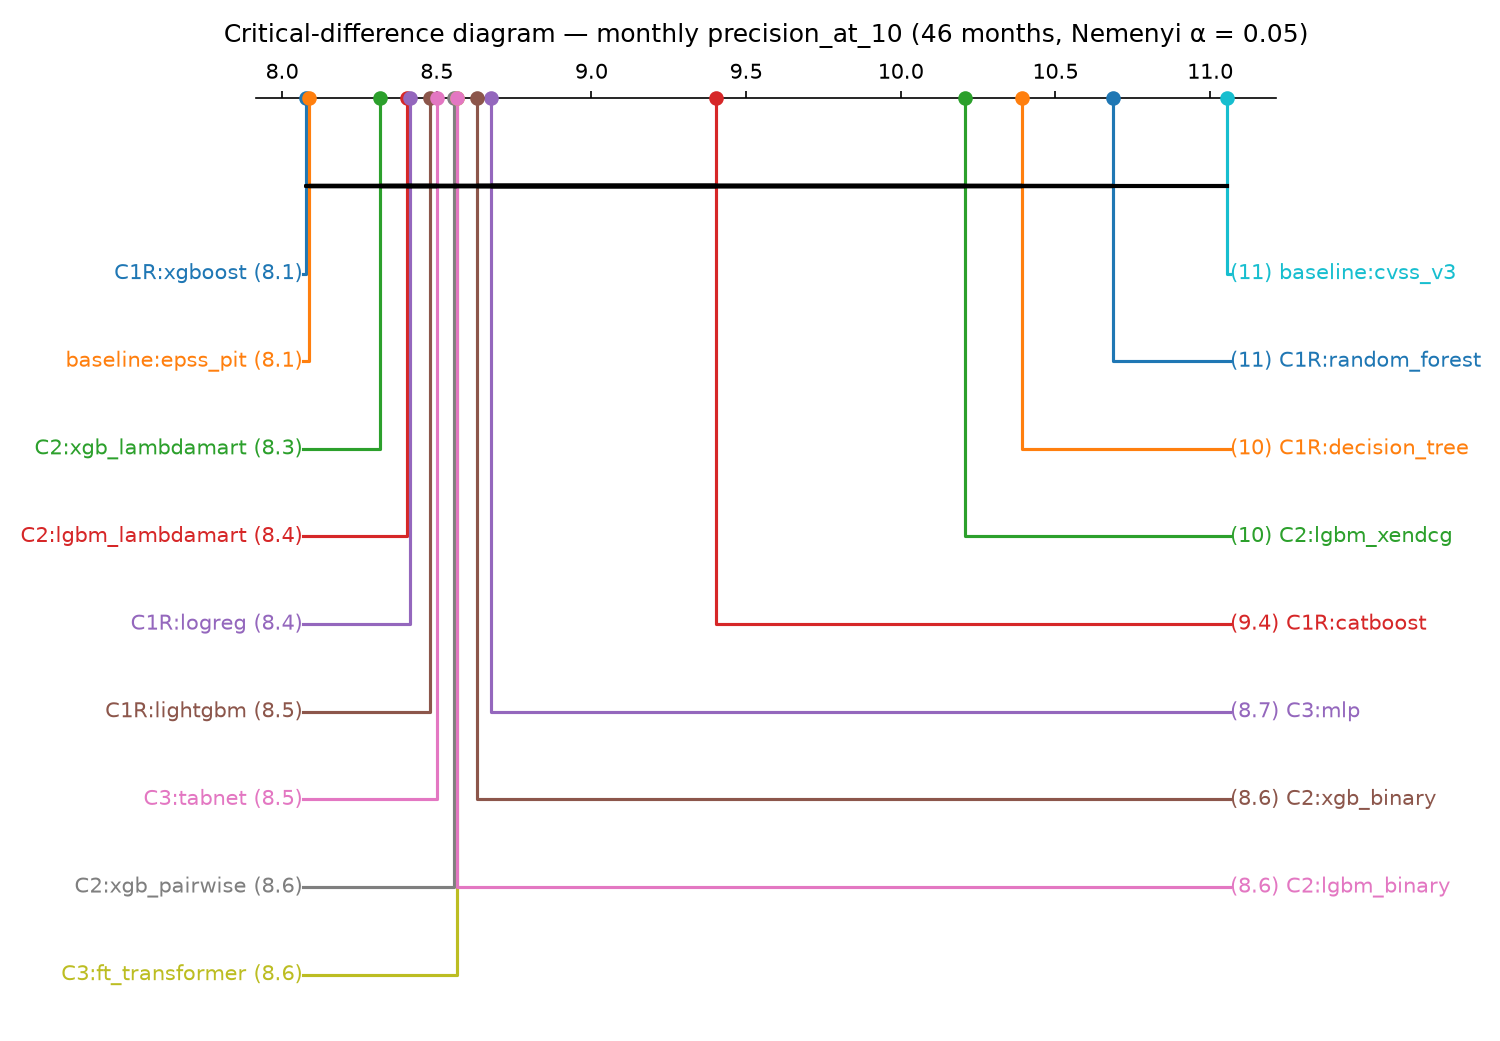

In [6]:
Image("outputs/c6_cd_precision_at_10.png")

## Wilcoxon vs best mean-rank model and vs EPSS-PIT (Holm-adjusted per metric)

In [7]:
w = pd.read_csv("outputs/c6_wilcoxon_holm.csv")
w[w.metric == "map"].round(4)

,metric,reference,method,median_diff_vs_ref,p_value,p_holm,nemenyi_p
64,map,C1R:logreg,C1R:catboost,-0.0008,0.1737,1.0000,0.9122
65,map,C1R:logreg,C1R:decision_tree,-0.0124,0.0000,0.0000,0.0000
66,map,C1R:logreg,C1R:lightgbm,-0.0021,0.2111,1.0000,0.9393
67,map,C1R:logreg,C1R:random_forest,-0.0077,0.0003,0.0039,0.2987
68,map,C1R:logreg,C1R:xgboost,-0.0004,0.4880,1.0000,0.9999
69,map,C1R:logreg,C2:lgbm_binary,-0.0006,0.3452,1.0000,1.0000
70,map,C1R:logreg,C2:lgbm_lambdamart,-0.0015,0.5807,1.0000,0.9947
71,map,C1R:logreg,C2:lgbm_xendcg,-0.0126,0.0000,0.0000,0.0001
72,map,C1R:logreg,C2:xgb_binary,-0.0009,0.2585,1.0000,0.9997
73,map,C1R:logreg,C2:xgb_lambdamart,-0.0002,0.9827,1.0000,1.0000


In [8]:
w[(w.reference == "baseline:epss_pit") & (w.p_holm < 0.05)].round(4)

,metric,reference,method,median_diff_vs_ref,p_value,p_holm,nemenyi_p
63,ndcg_at_10,baseline:epss_pit,baseline:cvss_v3,0.0000,0.0024,0.0382,0.4028
81,map,baseline:epss_pit,C1R:decision_tree,-0.0043,0.0027,0.0433,0.0713
127,mrr,baseline:epss_pit,baseline:cvss_v3,-0.0296,0.0027,0.0433,0.8874


**Reading.**
- Methods differ (Friedman p < 1e-4 on MAP, P@10, NDCG@10, NDCG@100; MRR p = 0.08).
- **Top tier is flat.** On monthly MAP, logistic regression has the best mean rank (6.5), but after Holm correction the other eight gradient-boosted models (C1-R XGBoost/LightGBM/CatBoost and five C2 objectives), the MLP and point-in-time EPSS are **not distinguishable from it**. Significantly worse than LR: decision tree, random forest, XE-NDCG, FT-Transformer, TabNet and CVSS v3.
- **Nothing beats point-in-time EPSS month by month** after Holm correction, on any of the five metrics. The global PR-AUC advantage of LR over EPSS-PIT (C1-R, +0.0060 [0.0013, 0.0121]) does not survive as a per-month ranking advantage once 16 comparisons are corrected.
- CVSS v3 is in the bottom group on every metric — the H1 conclusion of Study B holds across all 15 models.
- Nemenyi (17 methods, 46 blocks) is conservative; the diagrams show wide cliques. Wilcoxon-Holm is reported alongside, never instead.